# KQC MunchQubits — two circular transmons with a resonant coupler and a floating double-pad qubit (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' `chips/munch_qubits.py` (class `MunchQubits`, default parameters; © IQM
Finland Oy, GPL-3.0, <https://github.com/iqm-finland/KQCircuits>; local copy
`other-libs/KQCircuits-main/.../kqcircuits/chips/munch_qubits.py`). Two grounded
`CircularTransmonSingleIsland` qubits (island radius 300 µm, two arc couplers each) are joined by a 9800 µm
resonant coupler (a = 3, b = 32 µm) with a meander between them; a floating `DoublePads` qubit sits below. Each
qubit has a readout resonator (11500, 12700, 8000 µm) from its coupler to a `SmoothCapacitor` on a T in one probe
line that crosses the chip from WN to EN, and a charge line (QB3's crosses the probe line on an airbridge).

This notebook **rebuilds** the chip with our components, routes, netlist and LOM on the Quantcore PDK — not a
replica. We distribute the rebuild under GPL-3.0.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm (SMA8 launchers on its edges), Quantcore die frame, device ID "EM1" |
| launchers | SMA8 (DL-QB1 = NW, DL-QB2 = NE, PL-1-OUT = EN, DL-QB3 = SE, PL-1-IN = WN), indent 800 µm | same assignment, indent **880 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm) |
| substrate | silicon εr 11.45 (KQC simulation default) | sapphire 650 µm, εr 10.25 |
| junctions | KQC Manhattan SQUIDs (assumed 6 / 10 nH) | Quantcore trilayer SQUIDs: the two big circular islands (C_Σ ≈ 212 / 222 fF) **sized for 4.05 GHz** (fingers 0.26 / 0.27 µm, R_n 43.3 / 41.7 kΩ, L_J 6.48 / 6.24 nH); the double-pad qubit the nominal PDK SQUID (2 × 0.25 × 0.6 µm, 45 kΩ, 6.73 nH) |
| cheese | KQC's whole-area ground grid (`with_grid`) | the same whole-area coverage with the PDK squares: chip `cheese: "chip"` puts 5 µm squares with 20 µm gaps (instead of KQC's 5 µm on a 10 µm step) over the whole die, at least 4 µm from the 3/0 keep-outs and clear of the frame markers and the device ID |
| elements, positions, routes | — | kept exactly; launcher legs derived from the launcher ports |
| placement | centred | centred (checked, no shift) |

**Kept exactly:** both circular qubits (all coupler, drive and SQUID parameters) at (3500, 7000) and
(6500, 7000); the DoublePads qubit with the chip's parameters (islands 1000 × 200 µm, gap 200 µm, ground gap
1400 × 900 µm, drive at (−1100, 400)) rotated 180° at (5000, 4000); the coupler path through (4500, 6500) →
(5500, 6500) with the total length 9800 µm and galvanic ends; the probe line with its three splitters (angles
180/90/0, lengths 50/150/50, with airbridges) at x = 3500, 5000, 6500 and y = 1500; the smooth capacitors (finger
control 3.32/4.21/1.46, 160 µm); the readout paths (bottom: capacitor corner → diagonal → up; top: coupler corner
→ 300 µm down; meander between) and total lengths; the charge-line paths including QB3's airbridge crossing.

**Simplified:** the probe line is four routes between the splitters instead of one waveguide with the splitters
inlined; the meanders are fitted by the router; `n_bridges` airbridges along the lines are left out. Both readout
ends are capacitive, so the readouts are λ/2 resonators, and the coupler (galvanic to both coupler arcs) is a λ/2
bus.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die with its five SMA8 launchers, the launchers and the pad rule, the probe line with its three splitters and readout capacitors, the three qubits, their λ/2 readouts, the resonant coupler between the circular pair, the charge lines, and then the whole chip (the sim groups, the centring, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `munchqubits.v1.ipynb`; both save the same `munchqubits.json`.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the complete file). The segment pictures go to `build/snapshots/munchqubits/` (not kept
in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import size_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc")               # design JSON + final snapshots
STEPS = Path("build/snapshots/munchqubits")  # step-by-step snapshots (build/ is not kept in the repo)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | 5 µm squares, 20 µm gaps, ≥ 4 µm from the 3/0 keep-outs: a band of 3 rows around them, or the whole die (`cheese: "chip"`); an original design's own rule or holes where it has them (chip param `cheese`: auto / pdk / chip / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer lays it out by hand: the die and its launchers, the readout line, the qubits,
their readout resonators, the coupling, the control lines, and then the whole chip. Each segment is one cell with one
picture of the chip so far (live, KLayout redraws after every cell). A route joins two ports, so a resonator is drawn
once both of its ends exist: the splitters and capacitors (placed by coordinates) come before the qubits, the readouts
after them. The PDK cheese (`cheese: "chip"`, ≈ 0.13 M holes over the whole die) is drawn in every build, so each picture rebuilds the whole chip:
the pictures stay at the v1's size, one per segment.

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with the Quantcore frame and KQC's SMA8 launcher assignment (five launchers) |
| 2 | the launchers and the pad rule (they come with the die: a look and a table) |
| 3 | the readout line: three probe-line splitters with the readout `SmoothCapacitor`s, the probe line WN → EN |
| 4 | the qubits: two circular transmons and the double-pad qubit, with their trilayer SQUIDs |
| 5 | the readout resonators: three λ/2 lines, qubit coupler → capacitor |
| 6 | the coupling: the 9800 µm resonant coupler (a λ/2 bus) between the two circular qubits |
| 7 | the control routing: three charge lines (QB3's crosses the probe line on an airbridge) |
| 8 | the whole chip: sim groups, centring, save |

## Design 1 · The die, its frame and the launchers

10 × 10 mm with KQC's SMA8 launcher assignment for this chip (only the assigned pads are drawn) and the chip name
"EM1" (device ID). `cheese: "chip"`: the PDK cheese over the whole die (KQC's source grids its whole ground plane, `with_grid=True`, 5 µm holes on a 10 µm step; the rebuild keeps that coverage with the PDK squares, 5 µm with 20 µm gaps, at least 4 µm from the 3/0 keep-outs). The Quantcore frame replaces KQC's ChipFrame.

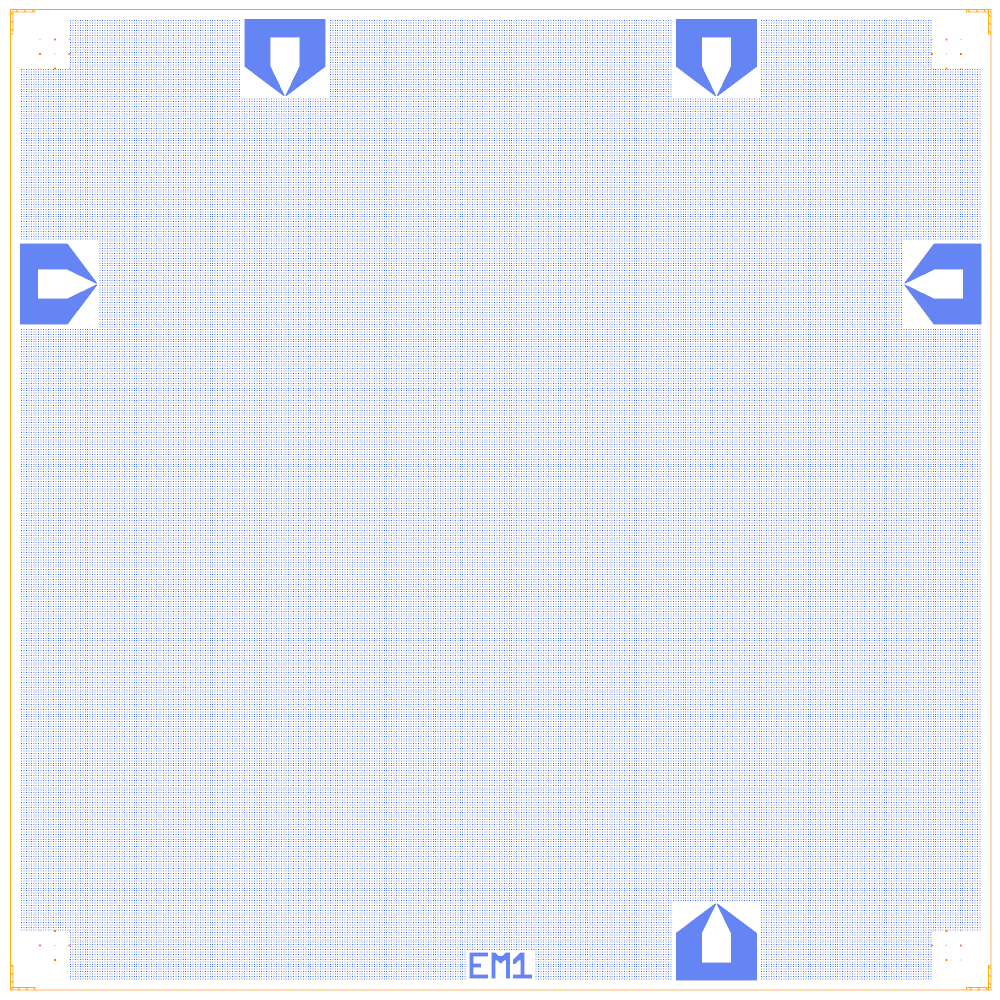

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout. The SMA8 launchers belong to the chip (the sample holder), not to the instances, so the pad count stays 0.

WindowsPath('build/snapshots/munchqubits/1_die.png')

In [5]:
pads = {1: "DL-QB1", 2: "DL-QB2", 3: "PL-1-OUT", 5: "DL-QB3", 8: "PL-1-IN"}   # KQC launcher assignment (SMA8)
d = Designer("munchqubits", box=(0, 0, 10000, 10000), launchers={"type": "SMA8", "assign": pads},
             chip={"name_chip": "EM1", "cheese": "chip"}, live=LIVE)
L = {name: f"chip.{name}" for name in pads.values()}
CHIP = dict(box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)   # the v1's full-chip picture
layout_step(d, STEPS / "1_die.png", **CHIP,
            note="The SMA8 launchers belong to the chip (the sample holder), not to the instances, so the "
                 "pad count stays 0.")

## Design 2 · Bond pads: the launchers and the pad rule

SMA8 launchers get `launcher_indent` = 100 + 300 + 300 + 180 = **880 µm** from the PDK pad rule (KQC: 800): the
outer etch edge is `frame.pad_edge` (100 µm) from the die edge. The launcher legs (Designs 3 and 7) start at
`corner(L[...])` (one turn radius out of the launcher port), so they follow the 80 µm shift.

The launchers came with the die (Design 1): nothing is added here. The table measures them, the picture zooms on PL-1-IN.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.DL-QB1 | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.DL-QB2 | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-1-OUT | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.DL-QB3 | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-1-IN | launcher port | w | port 880 µm in (indent from the rule) | ✓ |

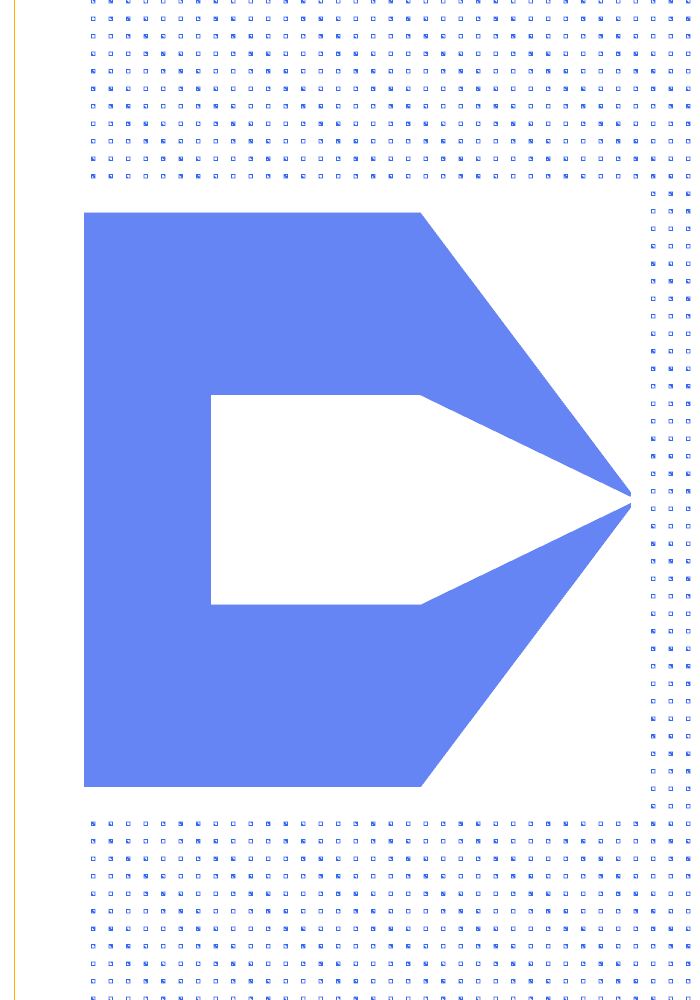

In [6]:
display(Markdown(pads_md(d)))
x, y = port_xy(d, L["PL-1-IN"])
snap(d, STEPS / "2_launcher.png", box=(-20, y - 400, x + 100, y + 400), size=(700, 1000), width=300);

## Design 3 · Readout: the probe line, its splitters and the readout capacitors

**Probe-line splitters**: three `WaveguideCoplanarSplitter`s at y = 1500 (angles 180/90/0, arms 50/150/50 µm,
airbridges on), and on each the readout's `SmoothCapacitor` (finger control 3.32 / 4.21 / 1.46, 160 µm) snapped
to the splitter's `b` arm.

The **probe line** WN → three splitters
→ EN, the diagonal launcher legs starting at the launcher corners. It is four routes between the splitters (KQC inlines the splitters in one waveguide). `corner(ref)` is KQC's `"<port>_corner"`
refpoint (one turn radius out along the port).

The splitters sit at the qubits' x (3500, 5000, 6500 µm) but are placed by coordinates, not from the qubits, so the
whole readout line comes first; each readout resonator joins its qubit to its capacitor in Design 5.

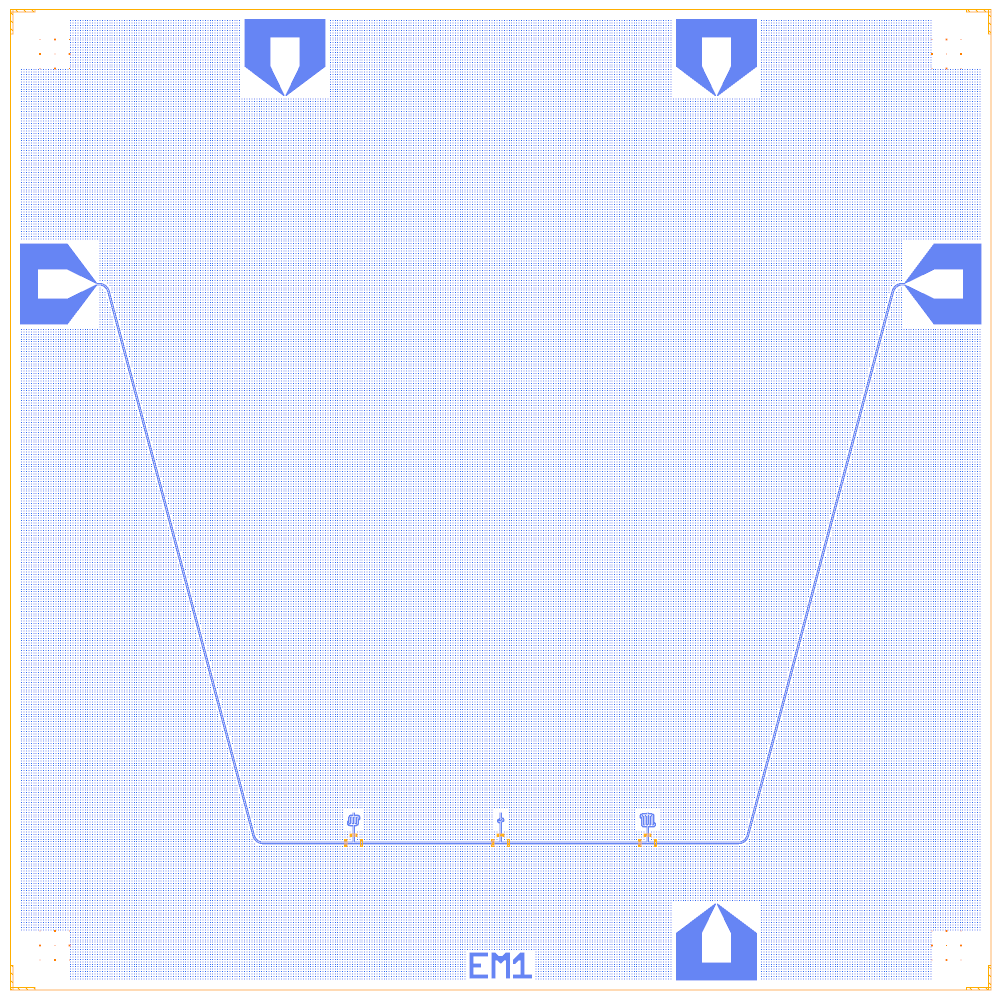

**On the chip so far:** 0 pads · 0 qubits · 6 other components · 4 routes · 0 declared couplings. **This step added** 6 component(s) `TQB1`, `TQB3`, `TQB2`, `RC1`, `RC2`, `RC3` and 4 route(s) `PL0`, `PL1`, `PL2`, `PL3`.

WindowsPath('build/snapshots/munchqubits/s3_probe_line.png')

In [7]:
def corner(ref, dist=100.0):                     # KQC "<port>_corner": one turn radius out along the port
    x, y, a = port_info(d, ref)
    return (x + dist * math.cos(math.radians(a)), y + dist * math.sin(math.radians(a)))


with d.batch():
    tee = {q: d.add(f"T{q}", "WaveguideCoplanarSplitter", at=(x, 1500), angles=[180, 90, 0], lengths=[50, 150, 50],
                    use_airbridges=True) for q, x in (("QB1", 3500), ("QB3", 5000), ("QB2", 6500))}
    for i, (q, fingers) in enumerate((("QB1", 3.32), ("QB2", 4.21), ("QB3", 1.46)), start=1):
        d.add(f"RC{i}", "SmoothCapacitor", snap="a", to=tee[q].b, finger_control=fingers, finger_width=10,
              ground_gap=10, finger_gap=5, fixed_length=160)
    d.route("PL0", L["PL-1-IN"], tee["QB1"].a, nodes=[corner(L["PL-1-IN"]), (2500, 1500)])
    d.route("PL1", tee["QB1"].c, tee["QB3"].a)
    d.route("PL2", tee["QB3"].c, tee["QB2"].a)
    d.route("PL3", tee["QB2"].c, L["PL-1-OUT"], nodes=[(7500, 1500), corner(L["PL-1-OUT"])])
layout_step(d, STEPS / "s3_probe_line.png", **CHIP)

## Design 4 · Qubit placement: two circular transmons and a double-pad qubit

**The junctions from the PDK rule.** KQC draws a SQUID in each qubit; `trilayer_junction` makes each a
Quantcore trilayer SQUID (KQC's `junction_width` = the straight finger, bent finger 0.6 µm). The two large
circular islands (C_Σ ≈ 212 / 222 fF without the junction, this design's LOM before the rebuild, hard-coded
here) would sit at ≈ 3.9–4.0 GHz with the nominal SQUID, below the PDK band, so `size_junction` sizes each for
4.05 GHz (R_n ≈ 43 / 42 kΩ, still in the window); the double-pad qubit gets the nominal SQUID.

**Circular transmons** (`CircularTransmonSingleIsland`, QB1 and QB2): a 300 µm-radius island in a 200 µm ground
gap, two arc couplers at 400 µm radius (`couplers_angle`, `couplers_a/b/width`, `couplers_arc_amplitude`), the
drive at 550 µm and the SQUID at 90°. Ports: `coupler_1`, `coupler_2`, `drive`.

**Double-pad qubit** (`DoublePads`, QB3): two floating 1000 × 200 µm islands 200 µm apart in a 1400 × 900 µm
ground gap, rotated 180° at (5000, 4000); ports `cplr`, `drive`.

The first picture is the chip so far, the second zooms on QB1 (no rebuild: the same build).

In [8]:
LJ_PDK = trilayer_junction("DoublePads")[1]["Lj_nH"]
JJ_PARAMS, JUNCTION = {}, {}
for q, c in (("QB1", 212.3), ("QB2", 222.1)):
    s = size_junction(4.05, c, n=2, c_includes_junction=False)
    JJ_PARAMS[q], JUNCTION[q] = trilayer_junction("CircularTransmonSingleIsland", lj_nH=s.lj_nH, squid=True)
JJ_PARAMS["QB3"], JUNCTION["QB3"] = trilayer_junction("DoublePads", lj_nH=LJ_PDK, squid=True)
display(Markdown("| qubit | cell parameters | LOM junction |\n|---|---|---|\n" + "\n".join(
    f"| {q} | `{JJ_PARAMS[q]}` | `{JUNCTION[q]}` |" for q in JJ_PARAMS)))

| qubit | cell parameters | LOM junction |
|---|---|---|
| QB1 | `{'junction_type': 'Quantcore Squid', 'junction_width': 0.26}` | `{'Lj_nH': 6.4754, 'Cj_fF': 15.6}` |
| QB2 | `{'junction_type': 'Quantcore Squid', 'junction_width': 0.27}` | `{'Lj_nH': 6.2356, 'Cj_fF': 16.2}` |
| QB3 | `{'junction_type': 'Quantcore Squid', 'junction_width': 0.25}` | `{'Lj_nH': 6.7344, 'Cj_fF': 15.0}` |

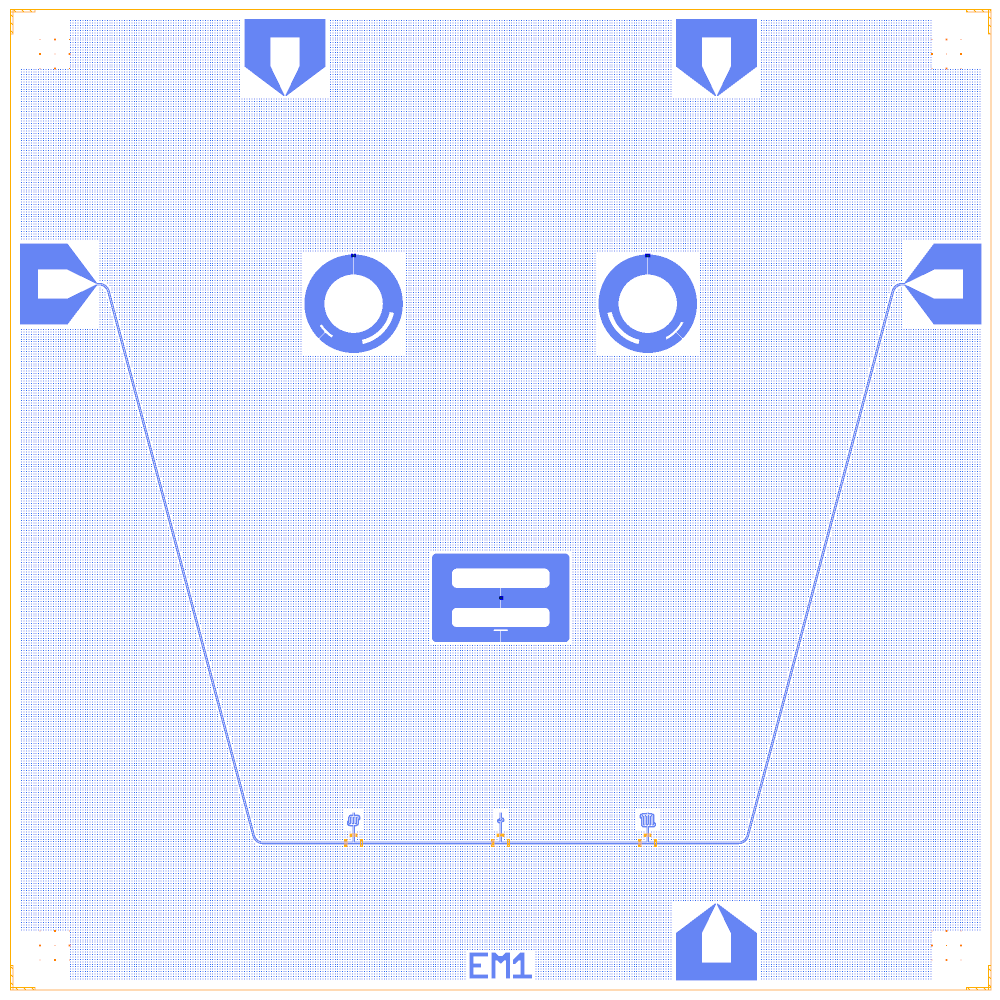

**On the chip so far:** 0 pads · 0 qubits · 9 other components · 4 routes · 0 declared couplings. **This step added** 3 component(s) `QB1`, `QB2`, `QB3`. KQC's qubit cells carry no Quantcore qubit category yet, so this line counts them among the other components.

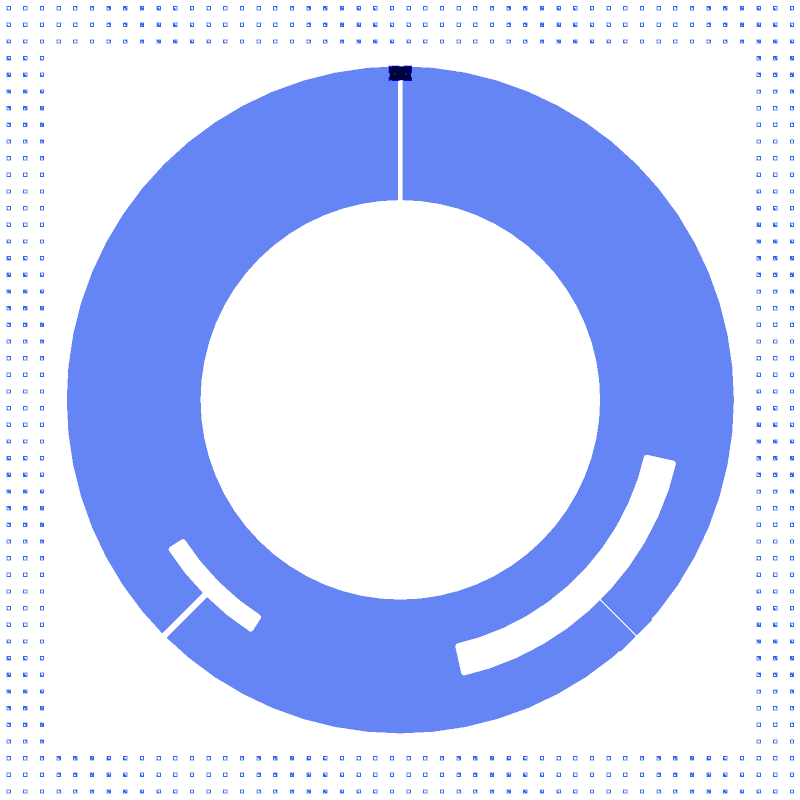

In [9]:
with d.batch():
    circ = dict(r_island=300, ground_gap=200, squid_angle=90, couplers_r=400, couplers_a=[10.0, 3.0],
                couplers_b=[6.0, 32.0], couplers_width=[30.0, 50.0], drive_distance=550.0)
    d.add("QB1", "CircularTransmonSingleIsland", at=(3500, 7000), junction=JUNCTION["QB1"], **JJ_PARAMS["QB1"],
          drive_angle=110, couplers_angle=[225.0, 315.0], couplers_arc_amplitude=[25.0, 65.0], **circ)
    d.add("QB2", "CircularTransmonSingleIsland", at=(6500, 7000), junction=JUNCTION["QB2"], **JJ_PARAMS["QB2"],
          drive_angle=70, couplers_angle=[315.0, 225.0], couplers_arc_amplitude=[35.0, 65.0], **circ)
    d.add("QB3", "DoublePads", at=(5000, 4000), rot=180, coupler_extent=[150, 20], island1_extent=[1000, 200],
          island2_extent=[1000, 200], island_island_gap=200, ground_gap=[1400, 900], drive_position=[-1100, 400],
          junction=JUNCTION["QB3"], **JJ_PARAMS["QB3"])
layout_step(d, STEPS / "s4_qubits.png", **CHIP,
            note="KQC's qubit cells carry no Quantcore qubit category yet, so this line counts them among "
                 "the other components.")
snap(d, STEPS / "s4_qb1.png", box=(2900, 6400, 4100, 7600), size=(800, 800), width=320);

## Design 5 · Readout: the three λ/2 resonators

**Readouts** (λ/2: both ends capacitive): from the qubit coupler's corner 300 µm down, a meander, then 100 µm and
a diagonal into the capacitor's corner, with KQC's totals 11500 / 12700 / 8000 µm. `meander=` makes each route that long: the
router puts what the waypoints leave over into one KQC `Meander` on the longest free straight, with no more turns than
keep it at least one bend radius wide.

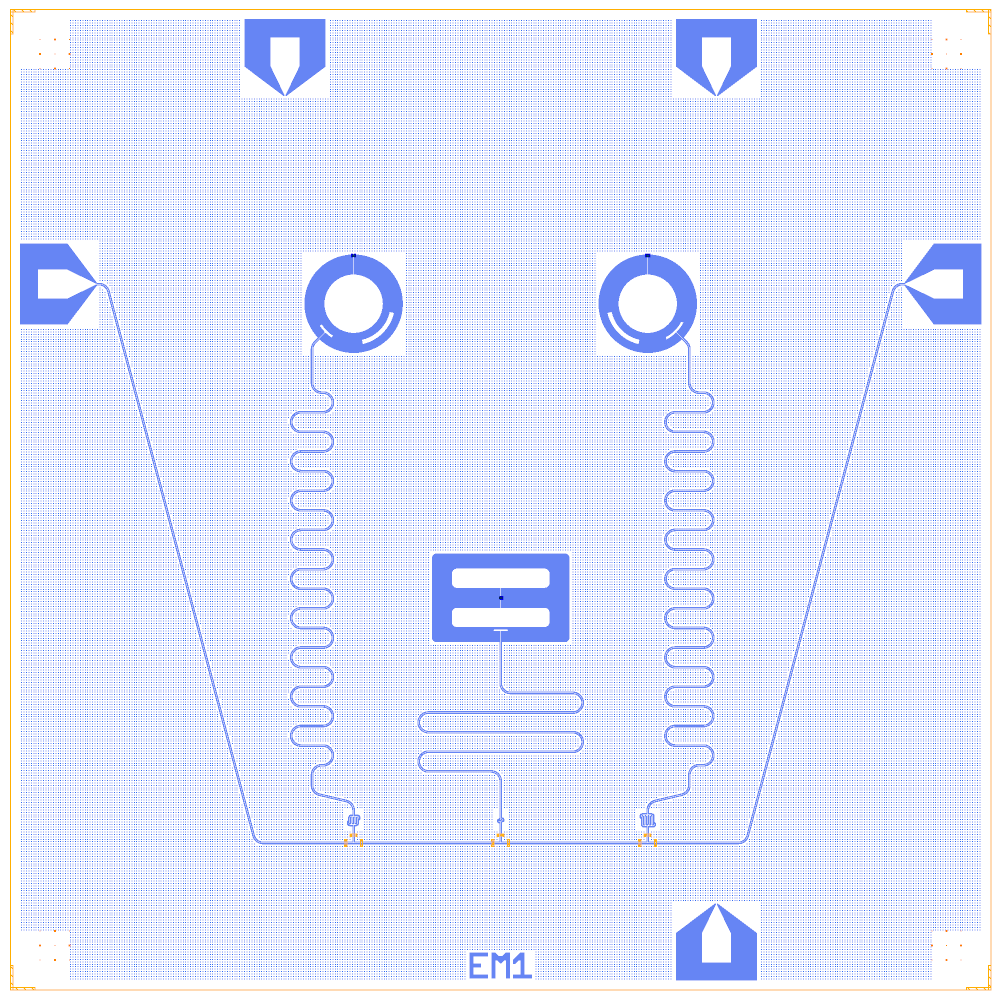

**On the chip so far:** 0 pads · 0 qubits · 9 other components · 7 routes · 0 declared couplings. **This step added** 3 route(s) `RR1`, `RR2`, `RR3`.

WindowsPath('build/snapshots/munchqubits/s5_readouts.png')

In [10]:
with d.batch():
    for i, (q, port, length) in enumerate((("QB1", "coupler_1", 11500), ("QB2", "coupler_1", 12700),
                                           ("QB3", "cplr", 8000)), start=1):
        qc, bc = corner(f"{q}.{port}"), corner(f"RC{i}.b")
        d.route(f"RR{i}", f"{q}.{port}", f"RC{i}.b", nodes=[qc, (qc[0], qc[1] - 300), (qc[0], bc[1] + 200),
                                                            (qc[0], bc[1] + 100), bc], meander=length)
layout_step(d, STEPS / "s5_readouts.png", **CHIP)

## Design 6 · Coupling: the resonant coupler

**Resonant coupler** QB1 ↔ QB2: 9800 µm, a = 3, b = 32 µm, galvanic at both arc couplers (`term1=0, term2=0`),
with the meander on the middle segment through (4500, 6500) → (5500, 6500). It is a λ/2 bus between the two
circular qubits' arc couplers (both ends galvanic): the only qubit–qubit coupling on the chip.

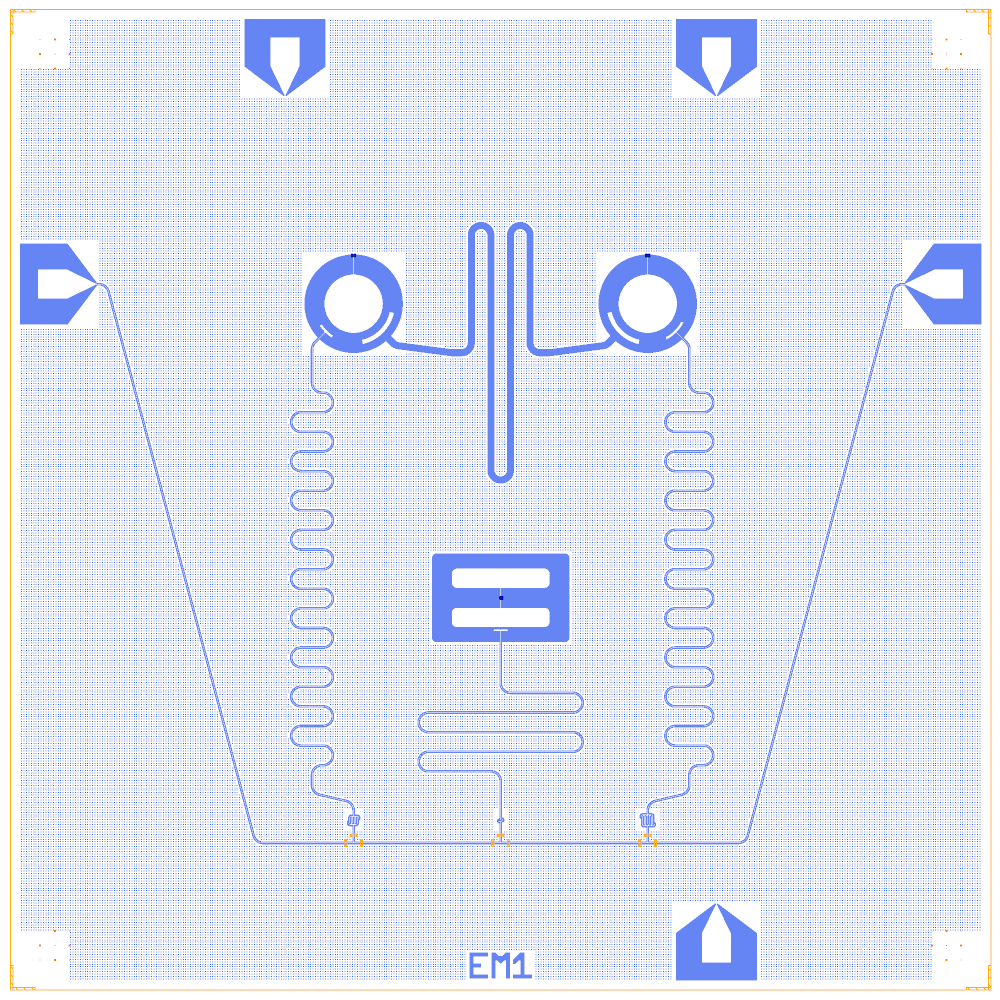

**On the chip so far:** 0 pads · 0 qubits · 9 other components · 8 routes · 0 declared couplings. **This step added** 1 route(s) `CPL`.

WindowsPath('build/snapshots/munchqubits/s6_coupler.png')

In [11]:
with d.batch():
    d.route("CPL", "QB1.coupler_2", "QB2.coupler_2", nodes=[corner("QB1.coupler_2"), (4500, 6500), (5500, 6500),
                                                            corner("QB2.coupler_2")],
            meander=9800, a=3, b=32, term1=0, term2=0)
layout_step(d, STEPS / "s6_coupler.png", **CHIP)

## Design 7 · Routing: the charge lines

**Charge lines** with a 6 µm
open end; QB3's crosses the probe line on an airbridge between the QB3 and QB2 splitters (`d.waypoint(...,
airbridge=True)`).

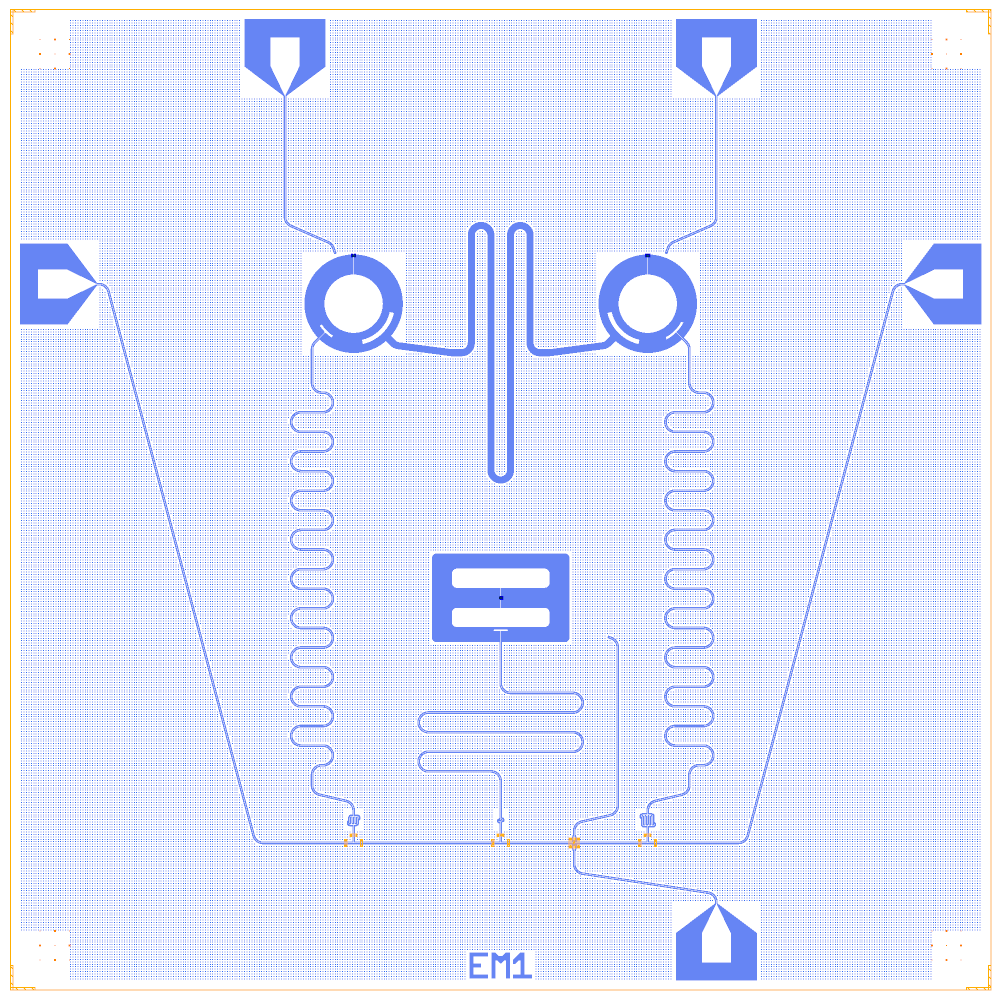

**On the chip so far:** 0 pads · 0 qubits · 9 other components · 11 routes · 0 declared couplings. **This step added** 3 route(s) `DL1`, `DL2`, `DL3`.

WindowsPath('build/snapshots/munchqubits/s7_charge_lines.png')

In [12]:
with d.batch():
    for i in (1, 2):
        c = corner(L[f"DL-QB{i}"])
        d.route(f"DL{i}", L[f"DL-QB{i}"], f"QB{i}.drive", nodes=[c, (c[0], c[1] - 1200), corner(f"QB{i}.drive")],
                term2=6)
    xc = (5000 + 6500) / 2
    dc = corner("QB3.drive")
    d.route("DL3", L["DL-QB3"], "QB3.drive", term2=6,
            nodes=[corner(L["DL-QB3"]), (xc, 1200), d.waypoint((xc, 1500), airbridge=True), (xc, 1700),
                   (dc[0], 1800), dc])
layout_step(d, STEPS / "s7_charge_lines.png", **CHIP)

## Design 8 · The whole chip: sim groups, centring, save

**Sim groups, centring, save.** A Q3D C-matrix job for the coupled circular pair with its resonant coupler and
one for QB3 with its readout and capacitor. `center_in_die` confirms the content is centred (no shift); then
`munchqubits.json` is saved with `save_design`, which compares it with the file it replaces (the previous
run's): the segments above changed how the chip is built (the readout line before the qubits, the coupler after
the readouts), not the chip, so it should say *same design*; the file keeps the previous key order.

centring shift (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/kqc/munchqubits.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer munchqubits: 9 instances, 11 routes, live=False> → examples\designs\kqc\munchqubits.json
{'RR1': 11500.0, 'RR2': 12700.0, 'RR3': 8000.0, 'CPL': 9800.0}


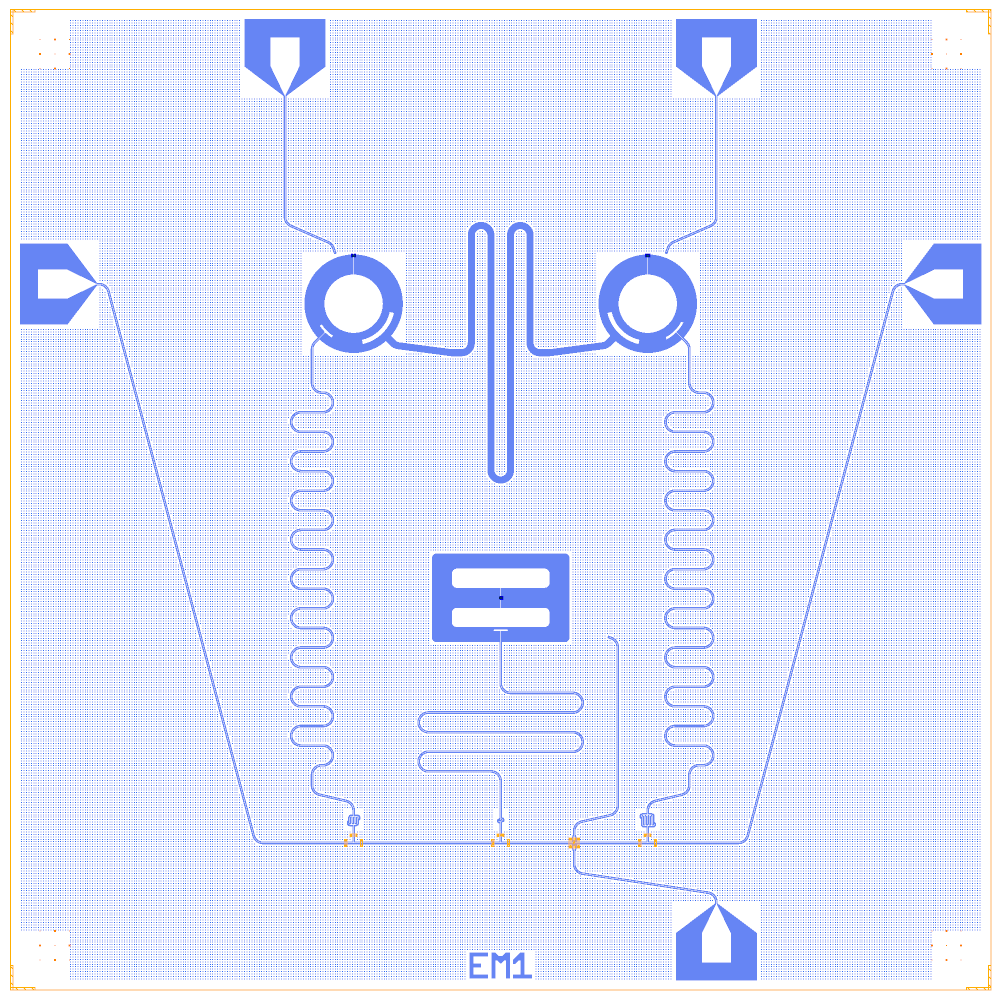

**On the chip so far:** 0 pads · 0 qubits · 9 other components · 11 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/munchqubits/4_routes.png')

In [13]:
d.sim_group("QB1_QB2_CPL", ["QB1", "QB2", "CPL"], analyses=["q3d_cmatrix"])
d.sim_group("QB3_RR3", ["QB3", "RR3", "RC3"], analyses=["q3d_cmatrix"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN, same = save_design(d, OUT / "munchqubits.json")
display(Markdown(same))
print(d, "→", DESIGN)
print({k: round(v, 1) for k, v in d.result.route_lengths().items() if k.startswith(("RR", "CPL"))})
layout_step(d, STEPS / "4_routes.png", **CHIP)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Expected here (from the v1 run):** DRC clean with no warnings. `pdk_rn` applies the 40–50 kΩ window to each SQUID's parallel R_n
(43.3 / 41.7 / 45 kΩ), so none is flagged.

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

Circular transmon → island node (C and SQUID to ground) + one node per arc coupler; DoublePads → two floating
island nodes with the SQUID between them and a coupler node. The coupler route (a meander between two
component ports, galvanic at both ends) is a λ/2 bus joining both arc-coupler nodes; the readouts are λ/2
resonators on the capacitor nodes; the probe line is one node between the WN and EN 50 Ω ports.

In [ ]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**QB1 and QB3 ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(("QB1.", "QB3.")))))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

Four groups: the two circular qubits with the resonant coupler (two qubit modes + the λ/2 bus, and the static ZZ
of QB1–QB2: circuit neighbours through the bus), and each qubit with its readout, capacitor and the whole probe
line (splitters + routes, so κ goes into the two 50 Ω launchers). Expected (from the v1 run): f_q ≈ 4.0–4.2 GHz for the circular
qubits (sized for 4.05 GHz; the readout loading moves them a little) and ≈ 5.3 GHz for the double-pad qubit
(nominal SQUID), the bus at ≈ 5.5 GHz. Both circular qubits were sized for the same frequency, so through the bus
they are nearly degenerate and their modes hybridise (participations ≈ 0.75 / 0.2 in the mode table): the ZZ
table says so, and a per-pair ZZ needs detuned junctions (or the C-matrix of the pair).

In [ ]:
groups = {"QB1+QB2+CPL": ["QB1", "QB2", "CPL"]}
for i, q in enumerate(("QB1", "QB2", "QB3"), start=1):
    groups[f"{q}+RR{i}"] = [q, f"RR{i}", f"RC{i}", "TQB1", "TQB3", "TQB2", "PL0", "PL1", "PL2", "PL3"]
results = simulate_groups(d, groups, max_modes=3)
display(Markdown(groups_md(results)))
display(Markdown("**Static ZZ between the two circular qubits (QuTiP, through the resonant coupler):**\n\n"
                 + zz_md({"QB1+QB2+CPL": results["QB1+QB2+CPL"]})))
for g, r in results.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(r)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each simulated group (QuCat; circles are qubits, squares
resonators — the bus `CPL` and the readouts; filled markers are the QuTiP dressed values), (b) the dispersive shift
|χ| of each resonator. In the v1 run the two circular qubits sit ≈ 0.1 GHz apart in the `QB1+QB2+CPL` group: through
the bus their modes hybridise (LOM 1).

In [ ]:
plot_lom(results, STEPS / "lom.png", title="munchqubits: LOM per sub-circuit")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The resonant coupler is a λ/2 bus: its length sets its frequency, and the qubit–qubit interaction it mediates
depends on how far the bus sits from the qubits. Shorten it from 9800 to 9000 µm (numbers from the v1 run): the bus mode moves up by
≈ 0.4 GHz (5.53 → 5.93 GHz), further from the qubits, so the bus's dispersive shift χ shrinks (≈ −8 → −6 MHz)
and QB1 moves up by ≈ 14 MHz; the two qubits stay hybridised. The change is made on a copy (`design_copy`), so
`munchqubits.json` keeps KQC's 9800 µm.

In [ ]:
def modes_delta_md(r0, r1):                      # before/after of every normal mode (QuCat)
    m0, m1 = {m.label: m for m in r0.modes}, {m.label: m for m in r1.modes}
    rows = ["| mode | kind | f before (GHz) | f after (GHz) | Δf (MHz) | A before (MHz) | A after (MHz) |",
            "|---|---|---|---|---|---|---|"]
    for k in m0:
        if k in m1:
            a, b = m0[k], m1[k]
            rows.append(f"| {k} | {a.kind} | {a.f_GHz:.4f} | {b.f_GHz:.4f} | {1e3 * (b.f_GHz - a.f_GHz):+.1f} | "
                        f"{a.anharmonicity_MHz:.1f} | {b.anharmonicity_MHz:.1f} |")
    return "\n".join(rows)

d2 = design_copy(DESIGN)
d2["CPL"].set(meander=9000)
after = simulate_groups(d2, {"QB1+QB2+CPL": groups["QB1+QB2+CPL"]}, max_modes=3)
display(Markdown("**CPL: 9800 → 9000 µm**\n\n" + modes_delta_md(results["QB1+QB2+CPL"], after["QB1+QB2+CPL"])))
display(Markdown(params_delta_md({"QB1+QB2+CPL": results["QB1+QB2+CPL"]}, after)))
display(Markdown("**Static ZZ after:**\n\n" + zz_md(after)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/kqc/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: the coupled circular pair with its resonant coupler, and QB3 with its readout and capacitor (Q3D).

The sim groups ask for Q3D only; `QB3_RR3` is also exported in eigenmode (Simulate 3): `build_simulation` exports any
analysis for a sim group, so the design file stays as it is.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/kqc/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix: one job per sim group (their own analysis)
jobs_eig = export_sims(DESIGN, ["QB3_RR3"], analysis="eigenmode_epr")   # the same group in eigenmode (Simulate 3)
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrices

`QB1_QB2_CPL`: both circular islands, the two `coupler_2` arcs the bus joins and the lines the box cuts (`DL1`, `DL2`,
`RR1`, `RR2`) as named nets; `QB3_RR3`: QB3's two floating islands, its coupler and the readout capacitor. Each net is
named after its LOM node, so the matrix goes straight into the circuit (Results 3). `fem_stage` solves each job with
`RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The `QB3_RR3` box in HFSS eigenmode: QB3's SQUID is a lumped L_J ‖ C_J sheet between its two islands, the lines the box
cuts (the probe line on both sides of QB3's splitter, the charge line) end in 50 Ω, so each mode's Q gives κ. pyEPR
(run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns the junction's participation into dressed
frequencies, α and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives S21 along the probe line through the same box, where RR3 (coupled to the line through RC3
and the splitter) shows up as a notch. The library cannot hand the solved eigenmode **mesh** itself to a driven setup
(no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim group and box, the
eigenmode job's mesh seeds, the adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the
eigenmode is solved) and a fast sweep around it.

In [ ]:
f_drv = results["QB3+RR3"].params.get("RR3.f_GHz")   # the LOM's RR3 frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "QB3_RR3", jobs_eig["QB3_RR3"][0], keep_eig["QB3_RR3"], f_guess=f_drv)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["QB3_RR3"]:
    display(Markdown(driven_md(keep_drv["QB3_RR3"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: a qubit; ≈ 0: a resonator), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
lom_f = {"QB3": results["QB3+RR3"].params.get("QB3.f_q_GHz"), "RR3": f_drv}
plot_eigenmodes(keep_eig, STEPS / "eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: QB3's mode is the one its SQUID participates in most, RR3's the remaining mode
nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr terms, κ = f/Q of the
50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds RR3's notch.

In [ ]:
fem_values = {}
if keep_eig["QB3_RR3"]:
    fem_values = epr_values(keep_eig["QB3_RR3"], {"QB3": "RR3"}, {"RR3": f_drv})
if keep_drv["QB3_RR3"]:
    fem_values.update({f"driven {k}": x for k, x in driven_values(keep_drv["QB3_RR3"], "RR3", f_drv).items()})
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(
        f"| `{k}` | {x:.5g} |" for k, x in fem_values.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q, α, f_r, χ and κ of QB3 / RR3 from "
          "pyEPR, and RR3's S21 notch.")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrices:** `fill` replaces the capacitance estimates of the simulated components by the
C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM runs again: the
circular pair with its bus on `QB1_QB2_CPL`, QB3 with its readout on `QB3_RR3`. **FEM directly:** the eigenmode
(pyEPR) values of Results 2. The left column is the LOM on the component estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

CHECKS = {"QB1+QB2+CPL": ("QB1_QB2_CPL", ["QB1.f_q_GHz", "QB1.alpha_MHz", "QB2.f_q_GHz", "QB2.alpha_MHz", "CPL.f_GHz"]),
          "QB3+RR3": ("QB3_RR3", ["QB3.f_q_GHz", "QB3.alpha_MHz", "RR3.f_GHz", "RR3.chi_MHz", "RR3.kappa_MHz"])}
rows = []
for g, (sg, keys) in CHECKS.items():
    est = results[g].params
    if keep_q3d.get(sg):
        on_fem = simulate(fill(d.lom(select=groups[g]).model, DESIGN, keep_q3d[sg]), max_modes=3).params
        rows += [(key, est.get(key), on_fem.get(key), f"LOM on the {sg} C-matrix") for key in keys]
    rows += [(key, est.get(key), fem_values[key], "eigenmode + pyEPR") for key in keys if key in fem_values]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts the LOM's f_q, α, f_r, χ and κ next to the LOM on "
          "the Q3D C-matrices and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

KQC's `MunchQubits` states no frequencies, so this notebook sets one as an exercise: **QB1 at 4.10 GHz**, ≈ 0.1 GHz
below where the LOM puts it with its readout (from the v1 run: 4.212 GHz). Both circular qubits were sized for the
same 4.05 GHz, so through the resonant coupler their modes hybridise (LOM 1); moving QB1 down detunes it from QB2. It is
reachable inside the PDK junction window: QB1's L_J goes from 6.48 nH to ≈ 6.8 nH, R_n ≈ 46 kΩ (`pdk_lj_bounds` keeps
the feedback within 40–50 kΩ). The readouts are not targeted.

The targets go on a copy (`target_copy` → `build/munchqubits_target.json`), so the design file keeps its own (none).
`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of the
circuit — on the Q3D values where a solve was kept — and picks one value per quantity (the consensus).
`loop.feedback` anchors a surrogate on that point and proposes the knobs that put the target inside its tolerance
(f_q ± 20 MHz); the proposal is written as revision 1, built and netlist-checked. The revision changes the LOM's
L_J; the drawn SQUID keeps its 0.26 µm straight fingers until it is sized again with
`trilayer_junction(..., lj_nH=..., squid=True)`. If the consensus table is empty, `loop.analyse` found no
qubit–readout pair it can tune here (see the log's requests): the cell then says so instead of proposing knobs.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {"QB1": {"f_q_GHz": 4.10}}   # the exercise target (GHz); add more here
DESIGN_T = target_copy(DESIGN, TARGETS)
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
the target is inside its tolerance or `MAX_ITER` revisions are made (`build/munchqubits/revisions/`). Without `RUN_FEM`
each revision is judged on the LOM. With `RUN_FEM = True` each revision's two Q3D component jobs are exported and solved first (`solve_rev`), so the
loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's value against the target
and the knob it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q3D component jobs, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in ('QB1_QB2_CPL', 'QB3_RR3')}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, STEPS / "iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `munchqubits.json` is the whole design: `qcc build examples/designs/kqc/munchqubits.json`
rebuilds `build/munchqubits.oas` + sidecar.

**The fab mask.** `export_fab` writes the PDK fab layers: base etch 1/0 with the cheese (source `build`: the PDK cheese over the whole die, 133 460 holes in a probe), the filled 3/0 keep-out (route + 10 µm, component + 24 µm, plus every cheese hole), the trilayer fingers 2/0 + 4/0 and spacer 50–53/0, airbridges 300/301 (the
splitters' and QB3's charge-line bridge), and the frame (100/0, 1000/0, 1001/0). Corner rounding is skipped
unless `FULL_FAB`; `qcc mask examples/designs/kqc/munchqubits.json` writes the complete file.

**Simulation export options.** No cheese in simulation exports; airbridges dropped unless `airbridges=True`;
`setup.geometry` reports what was left out.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "QB3_RR3", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

## Fab 2 · Snapshots

Full chip; QB1 with its two arc couplers; its SQUID; the QB3 readout capacitor on its probe-line splitter; the
die frame's south-west corner; QB1's SQUID region in the **fab view** (the mask from Fab 1: 1/0 with the PDK cheese holes, 3/0, the trilayer layers); and KQC's own `MunchQubits` built stand-alone for comparison. (The layout
snapshots show the PDK cheese, a light, even texture at full-chip scale, and draw the chip boundary 100/0 as an
outline; the fab view shows the cheese holes on 1/0 and on 3/0.)

In [ ]:
show_snapshot(d, OUT / "munchqubits.png", box=(-100, -100, 10100, 10100))   # chip only (KQC draws launcher names outside it)
show_snapshot(d, OUT / "munchqubits_qb1.png", box=(2900, 6400, 4100, 7600), width=480)
show_snapshot(d, OUT / "munchqubits_squid.png", box=(3440, 7440, 3560, 7560), width=360)
show_snapshot(d, OUT / "munchqubits_coupler.png", box=(4800, 1450, 5200, 1850), width=360)
show_snapshot(d, OUT / "munchqubits_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "munchqubits_fab.oas", OUT / "munchqubits_fab_qb1.png", box=(3250, 7250, 3750, 7750),
          size=(1200, 1200), width=420);

In [ ]:
from kqcircuits.chips.munch_qubits import MunchQubits
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
top = ref.create_cell("kqc_munchqubits")
top.insert(pya.DCellInstArray(MunchQubits.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "munchqubits_kqc_original.oas"))
snap_file(Path("build") / "munchqubits_kqc_original.oas", OUT / "munchqubits_kqc.png", box=(-100, -100, 10100, 10100),
          width=420);

## Summary

| | |
|---|---|
| **matches the source** | every KQC element with its parameters, positions and orientations; the SMA8 assignment; the coupler, probe-line, readout and charge-line paths and lengths (9800, 11500, 12700, 8000 µm); the sim groups; the whole-area cheese coverage (with the PDK squares instead of KQC's grid) |
| **differs (PDK)** | Quantcore die frame; launchers 80 µm further in (outer etch 100 µm, `frame.pad_edge`); sapphire; trilayer SQUIDs (circular qubits sized for 4.05 GHz, the double-pad qubit at the nominal SQUID ≈ 5.3 GHz) |
| **simplified** | four probe-line routes between the splitters; router-fitted meanders; no `n_bridges` |
| **PDK design warnings** | none |
| **FEM** | 2 Q3D jobs, QB3's eigenmode and driven jobs exported (`build/jobs/munchqubits_*`), not solved here |
| layout | built in eight segments (die and launchers, the launcher check, the probe line with its splitters and capacitors, the qubits, the readouts, the resonant coupler, the charge lines, the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target on a copy (QB1 4.10 GHz): `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`) |
| open | the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells; the revision's drawn SQUID keeps its fingers (size it with `trilayer_junction`) |